<a href="https://colab.research.google.com/github/KenzaBi/Portfolio/blob/main/Projet_Estimation_Appartements.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Projet 1 — Estimer le prix d’un appartement à Paris

## Objectif

L’agence fictive Clés de Lutèce souhaite proposer une première estimation en ligne du prix d’un appartement à Paris.

À partir des ventes de 2025 fournies, nous construirons un modèle de régression linéaire. Nous comparerons son erreur à celle d’une règle simple et analyserons ses limites pour recommander à l’agence si, et sous quelles conditions, elle peut utiliser cet outil.

## 1. Inspection des données

Nous examinons la structure du fichier, les valeurs manquantes et les éventuelles incohérences avant de décider des traitements à appliquer.

In [111]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.metrics import mean_absolute_error

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression

In [112]:
brutes = pd.read_csv("/content/ventes_appartements_paris_2025.zip")

print("Dimensions du tableau :", brutes.shape)
brutes.head()

Dimensions du tableau : (29503, 9)


,id_vente,mois,arrondissement,surface_m2,surface_carrez_m2,nb_pieces,nb_lots,nb_dependances,prix_eur
0,1,2025-11,16,34.0,33.50,2.0,1,0,400000.0
1,2,2025-09,15,25.0,19.56,2.0,2,1,178000.0
2,3,2025-06,16,235.0,235.47,7.0,1,5,2480000.0
3,4,2025-03,20,30.0,30.08,1.0,2,2,270000.0
4,5,2025-04,15,80.0,NaN,3.0,1,0,733475.0


Le fichier contient 29 503 lignes et 9 colonnes. Chaque ligne décrit une vente d’appartement, éventuellement accompagnée de dépendances ou de plusieurs lots. L’aperçu montre une surface Carrez manquante ; nous allons vérifier les valeurs manquantes dans l’ensemble du fichier.

Nous examinons les types des colonnes et les valeurs manquantes, puis les statistiques descriptives pour repérer d’éventuelles valeurs incohérentes ou extrêmes.

In [113]:
brutes.info()
print(brutes.isna().sum())
brutes[["surface_m2", "surface_carrez_m2", "nb_pieces","nb_lots", "nb_dependances", "prix_eur"]].describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29503 entries, 0 to 29502
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id_vente           29503 non-null  int64  
 1   mois               29503 non-null  object 
 2   arrondissement     29503 non-null  int64  
 3   surface_m2         29501 non-null  float64
 4   surface_carrez_m2  16576 non-null  float64
 5   nb_pieces          29501 non-null  float64
 6   nb_lots            29503 non-null  int64  
 7   nb_dependances     29503 non-null  int64  
 8   prix_eur           29493 non-null  float64
dtypes: float64(4), int64(4), object(1)
memory usage: 2.0+ MB
id_vente                 0
mois                     0
arrondissement           0
surface_m2               2
surface_carrez_m2    12927
nb_pieces                2
nb_lots                  0
nb_dependances           0
prix_eur                10
dtype: int64


,surface_m2,surface_carrez_m2,nb_pieces,nb_lots,nb_dependances,prix_eur
count,29501.000000,16576.000000,29501.000000,29503.000000,29503.000000,2.949300e+04
mean,52.858276,49.155905,2.383004,1.659289,0.879809,5.553915e+05
std,39.048357,48.099364,1.277437,0.806580,1.269627,6.674625e+05
min,1.000000,1.100000,0.000000,0.000000,0.000000,1.000000e+00
25%,28.000000,25.047500,1.000000,1.000000,0.000000,2.400000e+05
50%,42.000000,38.595000,2.000000,2.000000,1.000000,3.870000e+05
75%,67.000000,62.502500,3.000000,2.000000,1.000000,6.461000e+05
max,1469.000000,3241.000000,14.000000,20.000000,164.000000,4.400000e+07


Certaines informations sont manquantes : la surface Carrez n’est pas renseignée pour 12 927 ventes et le prix manque pour 10 ventes. On remarque aussi des valeurs inhabituelles, comme une surface habitable de 1 m², une surface Carrez de 1,1 m², un nombre de dépendances atteignant 164 et des prix compris entre 1 € et 44 millions d’euros. Nous regarderons les ventes concernées plus en détail avant de décider quoi conserver, car une valeur inhabituelle n’est pas forcément une erreur.

Nous affichons les ventes correspondant aux valeurs inhabituelles repérées pour examiner leurs autres caractéristiques avant de décider de leur traitement.

In [114]:
ventes_verif = brutes[ (brutes["surface_m2"] == brutes["surface_m2"].min()) | (brutes["surface_carrez_m2"] == brutes["surface_carrez_m2"].min())
  | (brutes["nb_dependances"] == brutes["nb_dependances"].max())
  | (brutes["prix_eur"] == brutes["prix_eur"].min()) | (brutes["prix_eur"] == brutes["prix_eur"].max())
]

ventes_verif

,id_vente,mois,arrondissement,surface_m2,surface_carrez_m2,nb_pieces,nb_lots,nb_dependances,prix_eur
92,93,2025-06,4,20.0,NaN,1.0,1,0,1.0
1227,1228,2025-01,11,37.0,NaN,3.0,1,1,1.0
1608,1609,2025-03,17,39.0,NaN,2.0,1,1,1.0
6531,6532,2025-06,17,128.0,NaN,5.0,1,1,1.0
9269,9270,2025-11,7,11.0,1.10,1.0,1,0,100.0
9717,9718,2025-06,19,29.0,NaN,2.0,1,0,1.0
10103,10104,2025-01,11,20.0,NaN,2.0,1,1,1.0
12587,12588,2025-10,17,30.0,NaN,2.0,1,0,1.0
13800,13801,2025-05,12,95.0,NaN,5.0,1,1,1.0
16581,16582,2025-06,12,85.0,NaN,3.0,1,1,1.0


La vente 17821 indique une surface habitable de 1 m² pour 2 pièces et une surface Carrez de 23,47 m², ce qui rend la surface habitable suspecte. D’autres ventes présentent des prix de 1 € ou un nombre de dépendances atteignant 164 ; nous conservons les données inchangées à ce stade, car nous ne disposons pas d’informations permettant de les corriger avec certitude.

## 2. Vérification des doublons

Nous recherchons les lignes entièrement identiques et les identifiants de vente répétés pour vérifier si certaines ventes apparaissent plusieurs fois.

In [115]:
print("Identifiants répétés :", brutes["id_vente"].duplicated().sum())
colonnes_sans_id = brutes.columns.drop("id_vente")
print( "Lignes identiques hors identifiant :", brutes.duplicated(subset=colonnes_sans_id).sum())

Identifiants répétés : 0
Lignes identiques hors identifiant : 21


Nous affichons les ventes dont les informations sont identiques, à l’exception de l’identifiant, pour les examiner avant de décider s’il faut les conserver ou les supprimer.

In [116]:
doublons_potentiels = brutes[ brutes.duplicated(subset=colonnes_sans_id, keep=False)]

doublons_potentiels.sort_values(by=list(colonnes_sans_id))

,id_vente,mois,arrondissement,surface_m2,surface_carrez_m2,nb_pieces,nb_lots,nb_dependances,prix_eur
13175,13176,2025-01,7,NaN,NaN,NaN,1,0,12450.0
16021,16022,2025-01,7,NaN,NaN,NaN,1,0,12450.0
19093,19094,2025-01,8,109.0,NaN,6.0,2,1,29250.0
29369,29370,2025-01,8,109.0,NaN,6.0,2,1,29250.0
16379,16380,2025-01,12,20.0,NaN,1.0,1,0,204.0
22131,22132,2025-01,12,20.0,NaN,1.0,1,0,204.0
23704,23705,2025-01,12,20.0,NaN,1.0,1,0,204.0
19440,19441,2025-01,16,53.0,NaN,3.0,1,1,5000.0
19511,19512,2025-01,16,53.0,NaN,3.0,1,1,5000.0
4817,4818,2025-02,9,58.0,NaN,3.0,1,0,500.0


Nous choisissons de conserver une seule ligne par combinaison identique hors identifiant, afin d’éviter de donner plusieurs fois du poids aux mêmes informations et de limiter leur présence à la fois dans l’apprentissage et le test. Cette décision peut toutefois écarter des ventes distinctes ayant les mêmes caractéristiques, car les adresses et les dates exactes ne sont pas disponibles.

In [117]:
sans_doublons = brutes.drop_duplicates(subset=colonnes_sans_id, keep="first").copy()
print("Lignes retirées :", len(brutes) - len(sans_doublons))
print("Lignes restantes :", len(sans_doublons))

Lignes retirées : 21
Lignes restantes : 29482


## 3. Définition du périmètre

Nous concentrons l’étude sur les appartements de 9 à 200 m², situés dans les arrondissements de 1 à 20, avec 1 à 4 lots et au plus 3 dépendances. Ces limites s’appuient sur les distributions examinées et réduisent la présence de ventes complexes, sans garantir que chaque vente concerne un appartement seul.

Nous retenons également un prix compris entre 3 000 et 30 000 €/m². Les montants très faibles peuvent correspondre à des informations incorrectes ou à des opérations particulières, comme les 90 m² vendus 2 €. Les prix très élevés peuvent concerner des biens exceptionnels que notre outil ne vise pas.

N.B: Ces seuils sont des choix de travail, pas des seuils officiels.

In [118]:
# Créer une copie pour préparer le périmètre
donnees = sans_doublons.copy()

# Ne pas diviser par une surface absente ou non positive
surface_utilisable = donnees["surface_m2"].where(
    donnees["surface_m2"] > 0
)

donnees["prix_m2"] = donnees["prix_eur"] / surface_utilisable

# Définir les règles
surface_ok = donnees["surface_m2"].between(9, 200)
arrondissement_ok = donnees["arrondissement"].between(1, 20)
lots_ok = donnees["nb_lots"].between(1, 4)
dependances_ok = donnees["nb_dependances"].between(0, 3)
prix_ok = donnees["prix_m2"].between(3_000, 30_000)

# Examiner les exclusions de chaque règle séparément
print("Hors règle de surface :", (~surface_ok).sum())
print("Hors règle d’arrondissement :", (~arrondissement_ok).sum())
print("Hors règle de lots :", (~lots_ok).sum())
print("Hors règle de dépendances :", (~dependances_ok).sum())
print("Hors règle de prix au m² :", (~prix_ok).sum())

# Appliquer les règles sur les caractéristiques
avant_filtre_prix = donnees[
    surface_ok
    & arrondissement_ok
    & lots_ok
    & dependances_ok
].copy()

# Appliquer ensuite le filtre de prix au m²
propres = avant_filtre_prix[
    avant_filtre_prix["prix_m2"].between(3_000, 30_000)
].copy()

print("Ventes après déduplication :", len(sans_doublons))
print("Ventes conservées :", len(propres))
print("Total écarté :", len(sans_doublons) - len(propres))

nb_ecartees_prix = len(avant_filtre_prix) - len(propres)

print("Exclusions supplémentaires du filtre au m² :", nb_ecartees_prix)
print(
    "Pourcentage correspondant :",
    round(100 * nb_ecartees_prix / len(avant_filtre_prix), 2),
    "%"
)

# Le prix au m² contient le prix réel : ne pas le garder comme prédicteur
propres = propres.drop(columns="prix_m2")

# Un nombre de pièces inférieur à 1 est traité comme manquant
propres.loc[propres["nb_pieces"] < 1, "nb_pieces"] = np.nan

Hors règle de surface : 456
Hors règle d’arrondissement : 0
Hors règle de lots : 288
Hors règle de dépendances : 267
Hors règle de prix au m² : 1039
Ventes après déduplication : 29482
Ventes conservées : 27594
Total écarté : 1888
Exclusions supplémentaires du filtre au m² : 961
Pourcentage correspondant : 3.37 %


Les ventes sans prix ou sans surface habitable sont écartées, car leur prix au m² ne peut pas être calculé. Les nombres de pièces manquants sont conservés et pourront être remplacés dans le pipeline.

Le filtrage utilise le prix réel : l’évaluation finale concernera uniquement les ventes respectant ce périmètre. Pour un nouvel appartement, nous ne pourrons pas vérifier à l’avance sa position dans la plage de prix au m².

## 4. Exploration des données

Nous examinons la répartition des prix, leur relation avec la surface et les différences entre arrondissements. Les observations concernent uniquement les ventes conservées dans notre périmètre.

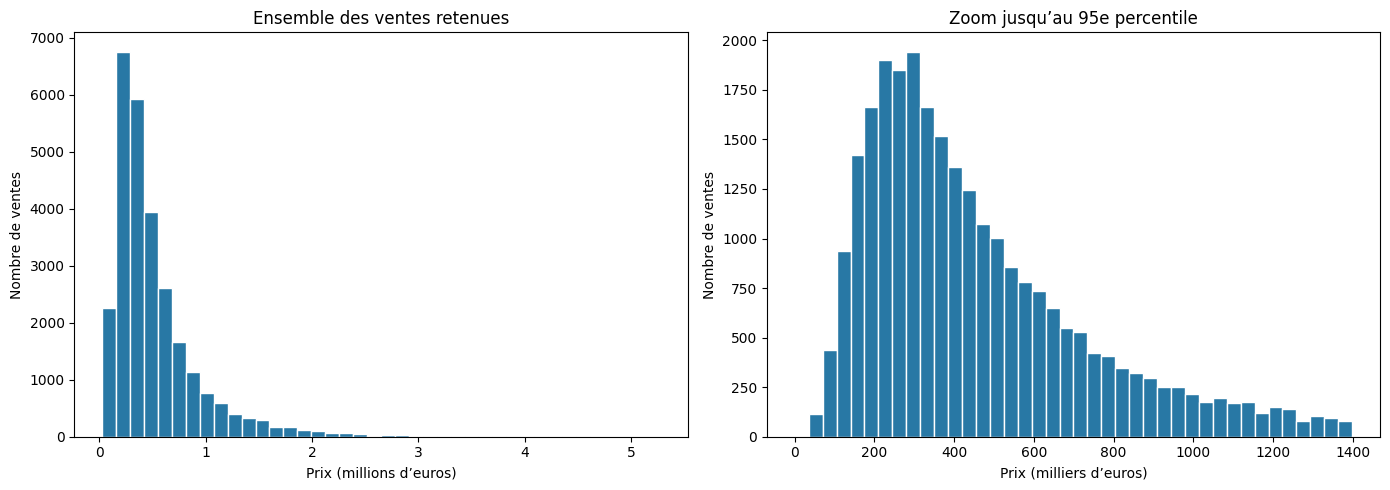

Prix moyen : 525627.97 €
Prix médian : 394807.5 €
Limite du zoom : 1398885.0 €


In [119]:
prix = propres["prix_eur"]
limite_zoom = prix.quantile(0.95)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(
    prix / 1_000_000,
    bins=40,
    color="#2878A5",
    edgecolor="white"
)
axes[0].set_title("Ensemble des ventes retenues")
axes[0].set_xlabel("Prix (millions d’euros)")
axes[0].set_ylabel("Nombre de ventes")

axes[1].hist(
    prix / 1_000,
    bins=40,
    range=(0, limite_zoom / 1_000),
    color="#2878A5",
    edgecolor="white"
)
axes[1].set_title("Zoom jusqu’au 95e percentile")
axes[1].set_xlabel("Prix (milliers d’euros)")
axes[1].set_ylabel("Nombre de ventes")

plt.tight_layout()
plt.show()

print("Prix moyen :", round(prix.mean(), 2), "€")
print("Prix médian :", round(prix.median(), 2), "€")
print("Limite du zoom :", round(limite_zoom, 2), "€")

Le prix médian est de 394 807,50 €, contre une moyenne de 525 627,97 €. Les ventes les plus chères tirent la moyenne vers le haut. Le zoom, limité à 1 398 885 €, facilite la lecture de la majorité des prix, sans retirer les ventes plus chères des données.

Nous examinons si le prix augmente généralement avec la surface et si des appartements de même taille présentent des prix différents.

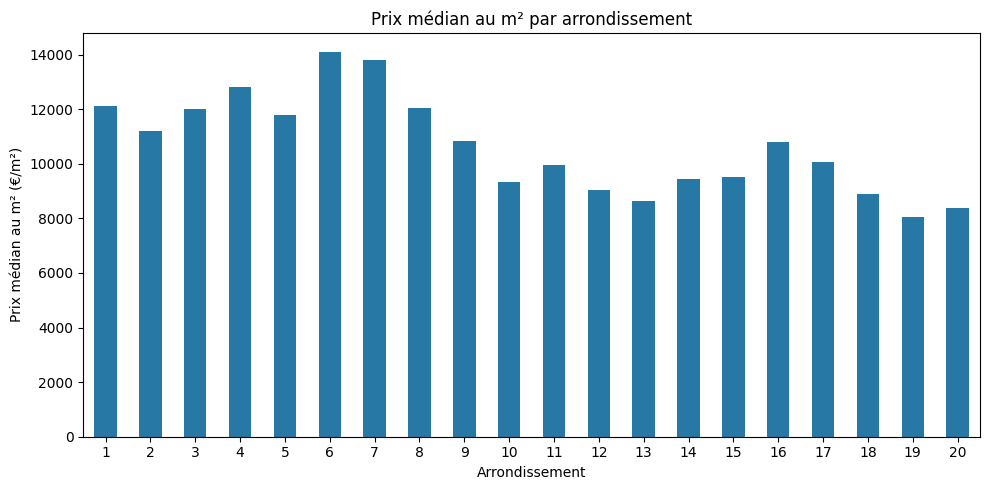

,prix_m2
arrondissement,
1,12102.63
2,11188.12
3,12000.00
4,12820.50
5,11798.88
6,14096.00
7,13807.34
8,12028.57
9,10838.24


In [120]:
exploration = propres.copy()

exploration["prix_m2"] = (
    exploration["prix_eur"] / exploration["surface_m2"]
)

prix_arrondissement = (
    exploration.groupby("arrondissement")["prix_m2"].median()
)

plt.figure(figsize=(10, 5))

prix_arrondissement.plot(
    kind="bar",
    color="#2878A5"
)

plt.xlabel("Arrondissement")
plt.ylabel("Prix médian au m² (€/m²)")
plt.title("Prix médian au m² par arrondissement")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

display(prix_arrondissement.round(2).to_frame())

Le prix médian au m² varie nettement selon l’arrondissement : il atteint 14 096 € dans le 6ᵉ, contre 8 052 € dans le 19ᵉ, soit un écart de 6 044 €/m². Ces différences suggèrent que l’arrondissement peut être utile pour estimer le prix, même si les biens vendus diffèrent aussi par d’autres caractéristiques.

Nous examinons également le prix selon la surface pour observer la tendance et les écarts entre biens de même taille.

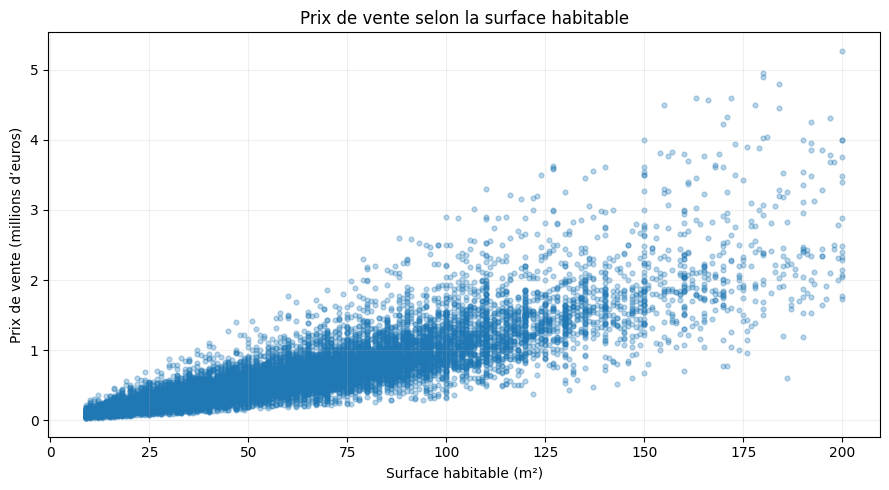

In [121]:
plt.figure(figsize=(9, 5))
plt.scatter(propres["surface_m2"], propres["prix_eur"] / 1_000_000, alpha=0.3, s=12)
plt.xlabel("Surface habitable (m²)")
plt.ylabel("Prix de vente (millions d’euros)")
plt.title("Prix de vente selon la surface habitable")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

Le graphique permet d’examiner la relation surface-prix. Les prix restent différents à surface comparable : cette caractéristique ne détermine pas seule le prix. L’évaluation des modèles permettra de mesurer l’apport des autres informations.

## 5. Séparation des données

Nous réservons 20 % des ventes pour l’évaluation et utilisons les autres ventes pour construire et comparer les modèles. Les médianes et les paramètres de préparation seront calculés uniquement sur l’apprentissage.

Cette étude révise une première analyse dont le test a déjà été examiné : la nouvelle évaluation ne constitue donc pas une validation externe totalement indépendante.

In [122]:
variables = [
    "surface_m2",
    "arrondissement",
    "nb_pieces",
    "nb_dependances"
]

X = propres[variables].copy()
y = propres["prix_eur"].copy()

X_appr, X_test, y_appr, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

cv = KFold(n_splits=5, shuffle=True, random_state=42)
plis = list(cv.split(X_appr))

print("Ventes pour l’apprentissage :", len(X_appr))
print("Ventes pour le test :", len(X_test))

Ventes pour l’apprentissage : 22075
Ventes pour le test : 5519


Les 27 594 ventes retenues sont réparties en deux ensembles : 22 075 pour l’apprentissage, soit environ 80 %, et 5 519 pour le test, soit environ 20 %. Les versions seront comparées sur l’apprentissage, puis la version retenue sera évaluée sur le test.

## 6. Référence des agents

La référence estime un prix en multipliant la surface par le prix médian au m² de l’arrondissement. Cette règle simple fournit un prix unique, sans fourchette.

Nous la mesurons par validation croisée sur l’apprentissage. À chaque tour, les médianes sont calculées sans utiliser les ventes de validation.

In [123]:
def reference_agents(X_entrainement, y_entrainement, X_validation):
    base = X_entrainement.copy()
    base["prix_m2"] = y_entrainement / base["surface_m2"]

    medianes = base.groupby("arrondissement")["prix_m2"].median()
    mediane_globale = base["prix_m2"].median()

    prix_m2_estimes = X_validation["arrondissement"].map(medianes)

    # Repli si un arrondissement est absent de l’entraînement
    prix_m2_estimes = prix_m2_estimes.fillna(mediane_globale)

    predictions = X_validation["surface_m2"] * prix_m2_estimes

    return predictions

In [124]:
erreurs_reference_cv = []

for indices_appr, indices_valid in plis:
    X_entrainement = X_appr.iloc[indices_appr]
    y_entrainement = y_appr.iloc[indices_appr]

    X_validation = X_appr.iloc[indices_valid]
    y_validation = y_appr.iloc[indices_valid]

    predictions = reference_agents(
        X_entrainement,
        y_entrainement,
        X_validation
    )

    erreur = mean_absolute_error(y_validation, predictions)
    erreurs_reference_cv.append(erreur)

print(
    "MAE moyenne de la référence :",
    round(np.mean(erreurs_reference_cv), 2),
    "€"
)
print(
    "Écart-type :",
    round(np.std(erreurs_reference_cv), 2),
    "€"
)

MAE moyenne de la référence : 96431.58 €
Écart-type : 2510.65 €


La référence des agents, fondée sur la surface et le prix médian au m² de l’arrondissement, obtient une erreur absolue moyenne de 96 431,58 € en validation croisée. L’écart-type des cinq erreurs est de 2 510,65 €. Nous utiliserons ces résultats pour vérifier si la régression apporte une amélioration sur les mêmes découpages.

## 7. Construction du pipeline

Le pipeline remplace les valeurs numériques manquantes par la médiane, standardise les variables numériques et encode les catégories avant la régression linéaire.

Ces traitements sont appris uniquement sur les ventes utilisées pour entraîner le modèle, y compris pendant la validation croisée. L’arrondissement est traité comme une catégorie, car son numéro ne représente pas une quantité.

In [125]:
def fabriquer_pipeline(nombres, categories):
    traitement_nombres = Pipeline([
        ("manquantes", SimpleImputer(strategy="median")),
        ("standardisation", StandardScaler())
    ])

    traitements = [
        ("nombres", traitement_nombres, nombres)
    ]

    if categories:
        traitement_categories = Pipeline([
            ("manquantes", SimpleImputer(strategy="most_frequent")),
            ("encodage", OneHotEncoder(handle_unknown="ignore"))
        ])

        traitements.append(
            ("categories", traitement_categories, categories)
        )

    preparation = ColumnTransformer(traitements)

    pipeline = Pipeline([
        ("preparation", preparation),
        ("modele", LinearRegression())
    ])

    return pipeline

## 8. Comparaison des versions

Nous ajoutons une caractéristique à la fois pour comprendre son apport : l’arrondissement, le nombre de pièces, puis les dépendances. Toutes les versions et la référence sont évaluées sur les mêmes cinq découpages de l’apprentissage.

In [126]:
VERSIONS = {
    "V1": (["surface_m2"], []),

    "V2": (
        ["surface_m2"],
        ["arrondissement"]
    ),

    "V3": (
        ["surface_m2", "nb_pieces"],
        ["arrondissement"]
    ),

    "V4": (
        ["surface_m2", "nb_pieces", "nb_dependances"],
        ["arrondissement"]
    )
}

resultats = []
erreurs_par_version = {}

resultats.append({
    "Version": "Référence",
    "MAE moyenne (€)": np.mean(erreurs_reference_cv),
    "Écart-type (€)": np.std(erreurs_reference_cv)
})

for nom, (nombres, categories) in VERSIONS.items():
    pipeline = fabriquer_pipeline(nombres, categories)
    colonnes_version = nombres + categories

    scores = cross_val_score(
        pipeline,
        X_appr[colonnes_version],
        y_appr,
        cv=plis,
        scoring="neg_mean_absolute_error"
    )

    erreurs = -scores
    erreurs_par_version[nom] = erreurs

    resultats.append({
        "Version": nom,
        "MAE moyenne (€)": erreurs.mean(),
        "Écart-type (€)": erreurs.std()
    })

tableau_resultats = pd.DataFrame(resultats)
display(tableau_resultats.round(2))

,Version,MAE moyenne (€),Écart-type (€)
0,Référence,96431.58,2510.65
1,V1,122850.65,3589.71
2,V2,113013.67,2622.81
3,V3,112942.01,2562.90
4,V4,112919.46,2544.86


V1 obtient une MAE moyenne de 122 850,65 €. L’arrondissement dans V2 la réduit à 113 013,67 €. V3 atteint 112 942,00 €, puis V4 112 919,45 €. Les gains liés aux pièces et dépendances restent faibles.

V4 a la plus faible MAE moyenne parmi les régressions comparées, mais son avantage sur les versions plus simples est très limité. La référence reste meilleure avec 96 431,58 €. Nous retenons V4 comme meilleur résultat moyen observé parmi les régressions, sans recommander de remplacer la règle des agents.

### Évaluation de la version retenue

Nous entraînons la régression retenue sur tout l’apprentissage, puis comparons son erreur à celle de la référence des agents sur les mêmes ventes du test. Nous ne changeons plus de version en fonction de ces résultats.

In [127]:
RETENUE="V4"
nombres, categories = VERSIONS[RETENUE]
colonnes = nombres + categories

modele = fabriquer_pipeline(nombres, categories)
modele.fit(X_appr[colonnes], y_appr)

predictions_test = modele.predict(X_test[colonnes])

predictions_reference_test = reference_agents(
    X_appr,
    y_appr,
    X_test
)

erreur_test = mean_absolute_error(y_test, predictions_test)

erreur_reference_test = mean_absolute_error(
    y_test,
    predictions_reference_test
)

print("Version retenue :", RETENUE)
print("MAE du modèle :", round(erreur_test, 2), "€")
print("MAE de la référence :", round(erreur_reference_test, 2), "€")
print(
    "Gain du modèle :",
    round(erreur_reference_test - erreur_test, 2),
    "€"
)

Version retenue : V4
MAE du modèle : 113980.49 €
MAE de la référence : 97547.19 €
Gain du modèle : -16433.29 €


Sur le test, V4 obtient une erreur absolue moyenne de 113 980,49 €, contre 97 547,19 € pour la référence des agents. Le gain affiché est négatif : l’erreur du modèle dépasse celle de la référence de 16 433,29 €, soit environ 16,8 %.

Ce résultat confirme le constat de la validation croisée : V4 est la meilleure régression parmi les versions comparées, mais elle n’améliore pas la règle des agents. La MAE est une moyenne et non une marge garantie pour chaque appartement.

## 9. Interprétation et analyse des erreurs

Nous modifions une caractéristique à la fois sur un appartement d’exemple pour comprendre les prédictions du modèle. Les écarts obtenus décrivent son comportement et ne prouvent pas un effet causal sur le prix réel.

In [128]:
appartement = pd.DataFrame([{
    "surface_m2": 45.0,
    "arrondissement": 11,
    "nb_pieces": 2.0,
    "nb_dependances": 1
}])

prix_initial = modele.predict(appartement[colonnes])[0]

modifications = [
    ("Surface : de 45 à 55 m²", "surface_m2", 55.0),
    ("Arrondissement : du 11e au 7e", "arrondissement", 7),
    ("Arrondissement : du 11e au 19e", "arrondissement", 19),
    ("Pièces : de 2 à 3", "nb_pieces", 3.0),
    ("Dépendances : de 1 à 2", "nb_dependances", 2)
]

effets = []

for description, colonne, valeur in modifications:
    if colonne in colonnes:
        variante = appartement.copy()
        variante[colonne] = valeur

        nouveau_prix = modele.predict(variante[colonnes])[0]

        effets.append({
            "Modification": description,
            "Prix initial (€)": prix_initial,
            "Nouveau prix (€)": nouveau_prix,
            "Écart (€)": nouveau_prix - prix_initial
        })

display(pd.DataFrame(effets).round(2))

,Modification,Prix initial (€),Nouveau prix (€),Écart (€)
0,Surface : de 45 à 55 m²,451294.45,573421.11,122126.66
1,Arrondissement : du 11e au 7e,451294.45,776345.18,325050.73
2,Arrondissement : du 11e au 19e,451294.45,364676.07,-86618.38
3,Pièces : de 2 à 3,451294.45,437219.10,-14075.34
4,Dépendances : de 1 à 2,451294.45,449368.25,-1926.20


Pour l’appartement de référence de 45 m² dans le 11ᵉ, avec 2 pièces et 1 dépendance, V4 estime le prix à 451 294,45 €.

En maintenant les autres caractéristiques fixes :
- Passer de 45 à 55 m² augmente l’estimation de 122 126,66 €, soit environ 12 212,67 € par m² supplémentaire.
- Passer du 11ᵉ au 7ᵉ arrondissement augmente l’estimation de 325 050,73 €.
- Passer du 11ᵉ au 19ᵉ arrondissement diminue l’estimation de 86 618,38 €.
- Passer de 2 à 3 pièces, à surface identique, diminue l’estimation de 14 075,34 €.
- Ajouter une dépendance diminue l’estimation de 1 926,20 €.

Les deux derniers effets invitent à la prudence. Ils décrivent les associations apprises par le modèle, sans prouver qu’une pièce ou une dépendance supplémentaire fait réellement baisser le prix. La relation entre surface et nombre de pièces, ainsi que les caractéristiques absentes des données, peuvent notamment compliquer leur interprétation.

Nous examinons les cinq erreurs absolues les plus élevées pour repérer les situations où le modèle est le moins fiable. Nous cherchons des points communs visibles dans le fichier, sans inventer des explications liées à l’état intérieur ou à la vue.

In [129]:
resultats_test = X_test.copy()

resultats_test["prix_reel"] = y_test
resultats_test["prix_estime"] = predictions_test

resultats_test["ecart"] = (
    resultats_test["prix_estime"] - resultats_test["prix_reel"]
)

resultats_test["erreur_absolue"] = resultats_test["ecart"].abs()

display(
    resultats_test.nlargest(5, "erreur_absolue").round(2)
)

,surface_m2,arrondissement,nb_pieces,nb_dependances,prix_reel,prix_estime,ecart,erreur_absolue
15831,180.0,8,5.0,1,4900000.0,2222436.96,-2677563.04,2677563.04
2623,127.0,4,5.0,3,3600000.0,1575553.49,-2024446.51,2024446.51
1279,180.0,16,5.0,3,4020000.0,2108387.78,-1911612.22,1911612.22
3058,137.0,3,4.0,3,3554028.0,1648902.73,-1905125.27,1905125.27
1496,192.0,4,5.0,1,4250000.0,2373229.20,-1876770.80,1876770.80


Les cinq plus grosses erreurs sont des sous-estimations d’environ 1,88 à 2,68 millions d’euros. Elles concernent des appartements de 127 à 192 m², vendus entre 3,55 et 4,9 millions d’euros.

Le modèle estime très mal certaines grandes ventes chères, même après le filtrage. Les données disponibles ne permettent pas d’expliquer précisément ces écarts. Nous ne retirons pas ces ventes après avoir examiné leurs erreurs sur le test.

## 10. Présentation et livraison des estimations

Nous calculons une prédiction de validation pour chaque vente d’apprentissage : le modèle qui la prédit n’a pas été entraîné sur cette vente. Les quantiles du rapport prix réel / prix estimé serviront à construire une fourchette empirique pour les estimations positives.

In [130]:
predictions_validation = pd.Series(
    index=y_appr.index,
    dtype=float
)

for indices_appr, indices_valid in plis:
    modele_temporaire = fabriquer_pipeline(nombres, categories)

    modele_temporaire.fit(
        X_appr.iloc[indices_appr][colonnes],
        y_appr.iloc[indices_appr]
    )

    predictions = modele_temporaire.predict(
        X_appr.iloc[indices_valid][colonnes]
    )

    index_validation = y_appr.iloc[indices_valid].index
    predictions_validation.loc[index_validation] = predictions

# Les rapports nécessitent des estimations strictement positives
estimations_positives = predictions_validation > 0

ratios = (
    y_appr.loc[estimations_positives]
    / predictions_validation.loc[estimations_positives]
)

print(
    "Prédictions non positives :",
    (~estimations_positives).sum()
)
print("Quantile 10 % :", round(ratios.quantile(0.10), 4))
print("Quantile 90 % :", round(ratios.quantile(0.90), 4))

Prédictions non positives : 106
Quantile 10 % : 0.7076
Quantile 90 % : 1.5556


Les prédictions de validation comprennent 106 estimations nulles ou négatives, qui ne sont pas utilisables comme prix affichés au client. Pour les estimations positives, les quantiles de 10 % et 90 % du rapport entre prix réel et prix estimé sont respectivement de 0,7076 et 1,5556.

Ces résultats définissent une fourchette empirique plus large que les facteurs initialement envisagés de 0,75 et 1,32. Ils montrent une incertitude importante et ne permettent pas d’affirmer que cette dernière fourchette couvre 80 % des ventes.

Vérification de la fourchette
Les facteurs sont déterminés sur l’apprentissage puis figés. Nous mesurons la couverture parmi les estimations positives et sur l’ensemble du test, en comptant les estimations non positives comme des échecs. Nous ne réajustons pas les facteurs à partir du test.

In [131]:
facteur_bas = ratios.quantile(0.10)
facteur_haut = ratios.quantile(0.90)

borne_basse_test = facteur_bas * predictions_test
borne_haute_test = facteur_haut * predictions_test
positives_test = predictions_test > 0

couvert_test = (
    positives_test
    & (y_test >= borne_basse_test)
    & (y_test <= borne_haute_test)
)

couverture_positive = couvert_test[positives_test].mean()
couverture_globale = couvert_test.mean()

print("Facteurs :", round(facteur_bas, 4), "et", round(facteur_haut, 4))
print("Estimations non positives du test :", (~positives_test).sum())
print("Couverture parmi les estimations positives :", round(100 * couverture_positive, 2), "%")
print("Couverture sur toutes les ventes du test :", round(100 * couverture_globale, 2), "%")

Facteurs : 0.7076 et 1.5556
Estimations non positives du test : 24
Couverture parmi les estimations positives : 79.44 %
Couverture sur toutes les ventes du test : 79.09 %


La fourchette couvre 79.44 % des prix réels parmi les estimations positives du test et 79.09 % de toutes les ventes du test. 24 estimations non positives sont comptées comme des échecs dans la couverture globale. Il s’agit d’une couverture observée dans notre périmètre, pas d’une garantie individuelle. Une largeur importante reste une limite pratique.

**Enregistrement, rechargement et estimations A/B**

Nous enregistrons le pipeline V4 et le rechargeons avant de prédire les appartements A et B. La valeur manquante du nombre de pièces de B sera traitée par le pipeline. Les bornes de présentation sont calculées après la prédiction ; elles ne correspondent pas au filtre de périmètre.

In [132]:
joblib.dump(modele, "modele_appartements_paris.joblib")
modele_charge = joblib.load("modele_appartements_paris.joblib")

appartements = pd.DataFrame([
    {"surface_m2": 45.0, "arrondissement": 11,
     "nb_pieces": 2.0, "nb_dependances": 1},
    {"surface_m2": 80.0, "arrondissement": 7,
     "nb_pieces": np.nan, "nb_dependances": 0}
], index=["Appartement A", "Appartement B"])

estimations = modele_charge.predict(appartements[colonnes])
estimations_avant = modele.predict(appartements[colonnes])
print("Prédictions conservées après rechargement :", np.allclose(estimations, estimations_avant))

resultats_appartements = appartements.copy()
resultats_appartements["estimation_eur"] = estimations
resultats_appartements["borne_basse_eur"] = facteur_bas * estimations
resultats_appartements["borne_haute_eur"] = facteur_haut * estimations
display(resultats_appartements.round(2))

# Conserver également les facteurs de présentation
joblib.dump(
    {"facteur_bas": facteur_bas, "facteur_haut": facteur_haut},
    "facteurs_fourchette.joblib"
)

Prédictions conservées après rechargement : True


,surface_m2,arrondissement,nb_pieces,nb_dependances,estimation_eur,borne_basse_eur,borne_haute_eur
Appartement A,45.0,11,2.0,1,451294.45,319347.93,702022.27
Appartement B,80.0,7,NaN,0,1205714.70,853195.73,1875579.40


['facteurs_fourchette.joblib']

Les estimations A/B illustrent le fonctionnement du prototype, sans valider leur exactitude : leurs prix réels ne sont pas connus. Une éventuelle présentation sous forme de fourchette devrait rester accompagnée d’une vérification par un agent. Nous ne recommandons pas une mise en ligne de V4 en l’état.

## Conclusion pour Clés de Lutèce
Nous avons étudié une première estimation des prix à partir des ventes parisiennes de 2025. Sur 29 503 lignes brutes, 21 répétitions hors identifiant ont été retirées, puis les règles de périmètre ont écarté 1 888 ventes. L’étude conserve 27 594 ventes : surfaces de 9 à 200 m², 1 à 4 lots, au plus 3 dépendances et prix de 3 000 à 30 000 €/m² dans Paris.

La meilleure régression moyenne parmi les quatre versions, V4, obtient une erreur absolue moyenne de 113 980,43 € sur le test, contre 97 547,19 € pour la règle des agents. Elle ne justifie donc pas de remplacer cette règle simple. Certaines grandes ventes chères restent fortement sous-estimées, et le modèle produit aussi des prix non positifs.

La fourchette empirique couvre 79.09 % de toutes les ventes du test. Elle montre l’incertitude mais ne garantit pas le prix d’un appartement et ne corrige pas les faiblesses du modèle. Nous recommandons de conserver V4 comme prototype d’étude et de ne pas la mettre en ligne en l’état. La référence demeure le meilleur point de comparaison dans cette analyse, sans remplacer une visite professionnelle.

Ces résultats concernent uniquement les ventes filtrées de 2025. L’adresse exacte, l’étage, la vue et l’état intérieur sont absents. Le filtrage sur le prix réel ne peut pas être vérifié à l’avance pour un nouveau propriétaire. Enfin, le test d’une première analyse avait déjà été examiné avant cette révision : une nouvelle évaluation indépendante serait nécessaire avant tout déploiement.